# Handcrafted Feature Group Analysis
In this notebook we study which groups of handcrafted acoustic features are the most useful for generator classification.
We use the previously extracted handcrafted features and the existing train and validation splits.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score

In [10]:
handcrafted_df = pd.read_csv(
    "../data/interim/handcrafted_features.csv"
)

In [4]:
train_df = handcrafted_df[handcrafted_df["split"] == "train"].copy()
val_df = handcrafted_df[handcrafted_df["split"] == "validation"].copy()

y_train = train_df["generator"]
y_val = val_df["generator"]

In [ ]:
energy_features = [
    "rms_mean",
    "rms_std",
]

temporal_features = [
    "zero_mean",
    "zero_std",
]

spectral_features = [
    "spectral_centroid_mean",
    "spectral_centroid_std",
    "spectral_bandwidth_mean",
    "spectral_bandwidth_std",
    "spectral_rolloff_mean",
    "spectral_rolloff_std",
]

mfcc_features = [col for col in handcrafted_df.columns if col.startswith("mfcc_")]

feature_groups = {
    "Energy": energy_features,
    "Temporal": temporal_features,
    "Spectral": spectral_features,
    "MFCC": mfcc_features,
    "All features": (
        energy_features
        + temporal_features
        + spectral_features
        + mfcc_features
    ),
}

## Feature group comparison

To understand which types of handcrafted features are the most useful, we test each feature group separately.

The same Logistic Regression model is used for every group, so the only thing that changes between experiments is the set of input features. This allows us to compare the groups fairly.

We use Macro F1 as the main metric because the task has five generator classes and we want each class to contribute equally to the final score.

In [7]:
results = []

for group_name, feature_cols in feature_groups.items():
    X_train = train_df[feature_cols]
    X_val = val_df[feature_cols]

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(
            max_iter=2000,
            random_state=42,
        )),
    ])

    model.fit(X_train, y_train)

    y_pred = model.predict(X_val)

    macro_f1 = f1_score(
        y_val,
        y_pred,
        average="macro",
    )

    results.append({
        "feature_group": group_name,
        "n_features": len(feature_cols),
        "macro_f1": macro_f1,
    })

In [8]:
results_df = (
    pd.DataFrame(results)
    .sort_values("macro_f1", ascending=False)
)

results_df

,feature_group,n_features,macro_f1
4,All features,36,0.765732
3,MFCC,26,0.723353
0,Energy,2,0.372663
2,Spectral,6,0.363033
1,Temporal,2,0.228384


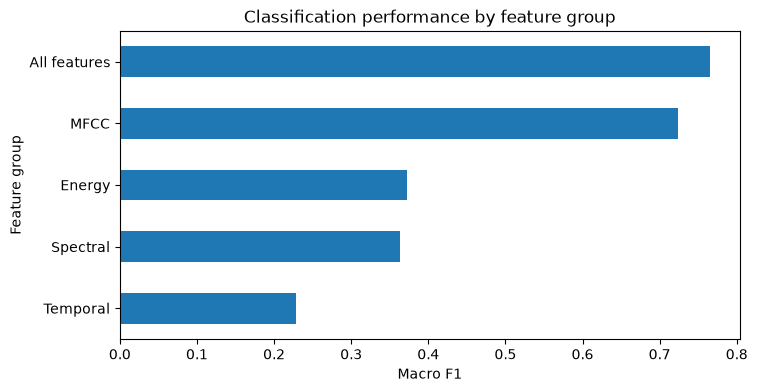

In [9]:
results_df.sort_values("macro_f1").plot(
    x="feature_group",
    y="macro_f1",
    kind="barh",
    legend=False,
    figsize=(8, 4),
)

plt.xlabel("Macro F1")
plt.ylabel("Feature group")
plt.title("Classification performance by feature group")
plt.show()

### Feature group observations

The results show that MFCCs are the strongest individual feature group for generator classification, reaching a Macro F1 of about 0.72.

Energy and spectral features perform much worse when used alone, with Macro F1 values around 0.37. Temporal features give the lowest result, which suggests that Zero Crossing Rate contains little useful information for this task on its own.

The best result is achieved when all handcrafted features are used together, with a Macro F1 of about 0.77. This is higher than using only MFCCs, which suggests that energy and spectral features provide some additional information.

Overall, the results suggest that MFCCs contain most of the useful handcrafted information, but combining different acoustic properties gives the best classification performance.

## Combining MFCCs with other feature groups

The previous experiment shows that MFCCs are the strongest individual feature group.

We now add the other feature groups to MFCCs separately to see which acoustic information provides the largest additional improvement beyond MFCCs.

In [11]:
extended_groups = {
    "MFCC only": mfcc_features,
    "MFCC + Energy": mfcc_features + energy_features,
    "MFCC + Spectral": mfcc_features + spectral_features,
    "MFCC + Temporal": mfcc_features + temporal_features,
    "All features": (
        mfcc_features
        + energy_features
        + spectral_features
        + temporal_features
    ),
}

In [12]:
extended_results = []

for group_name, feature_cols in extended_groups.items():
    X_train = train_df[feature_cols]
    X_val = val_df[feature_cols]

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(
            max_iter=2000,
            random_state=42,
        )),
    ])

    model.fit(X_train, y_train)

    y_pred = model.predict(X_val)

    macro_f1 = f1_score(
        y_val,
        y_pred,
        average="macro",
    )

    extended_results.append({
        "feature_group": group_name,
        "n_features": len(feature_cols),
        "macro_f1": macro_f1,
    })

In [13]:
extended_results_df = (
    pd.DataFrame(extended_results)
    .sort_values("macro_f1", ascending=False)
)

extended_results_df

,feature_group,n_features,macro_f1
4,All features,36,0.765732
2,MFCC + Spectral,32,0.754262
1,MFCC + Energy,28,0.749115
3,MFCC + Temporal,28,0.735509
0,MFCC only,26,0.723353


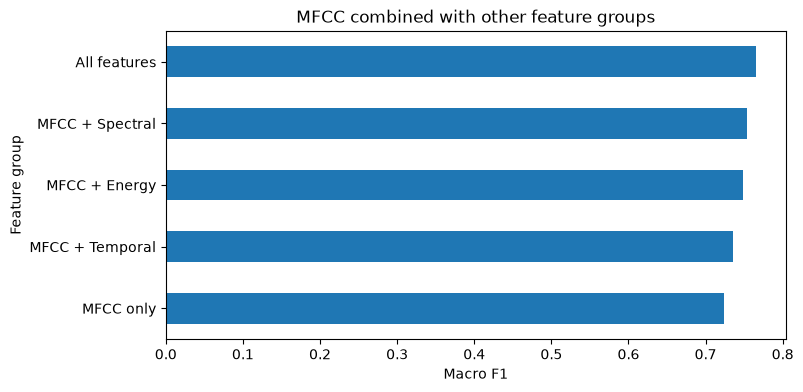

In [14]:
extended_results_df.sort_values("macro_f1").plot(
    x="feature_group",
    y="macro_f1",
    kind="barh",
    legend=False,
    figsize=(8, 4),
)

plt.xlabel("Macro F1")
plt.ylabel("Feature group")
plt.title("MFCC combined with other feature groups")
plt.show()

### Combined feature group results

The largest improvement comes from adding spectral features, but energy features also provide useful additional information. Temporal features give only a small improvement compared with MFCCs alone.

## Feature importance

The previous experiments compare groups of features. Now we look at individual features to see which ones are used most strongly by the Logistic Regression model.

The model is trained on the full handcrafted feature set. Because all features are scaled to a similar range, we can compare the Logistic Regression coefficients more fairly.

In [16]:
all_features = feature_groups["All features"]

X_train = train_df[all_features]
X_val = val_df[all_features]

model = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(
        max_iter=2000,
        random_state=42,
    )),
])

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](5,)","['MusicGen_medium','audioldm2','musicldm','mustango','stable_audio_open']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](36,)","['rms_mean','rms_std','zero_mean',...,'mfcc_12_std','mfcc_13_mean', 'mfcc_13_std']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,36
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [17]:
coefficients = model.named_steps["clf"].coef_

In [18]:
importance = np.mean(
    np.abs(coefficients),
    axis=0,
)

In [19]:
importance_df = pd.DataFrame({
    "feature": all_features,
    "importance": importance,
}).sort_values(
    "importance",
    ascending=False,
)

importance_df.head(10)

,feature,importance
12,mfcc_2_mean,1.143553
8,spectral_rolloff_mean,0.985040
32,mfcc_12_mean,0.863157
10,mfcc_1_mean,0.769716
11,mfcc_1_std,0.764467
1,rms_std,0.747979
6,spectral_bandwidth_mean,0.742877
28,mfcc_10_mean,0.650209
34,mfcc_13_mean,0.623196
30,mfcc_11_mean,0.545930


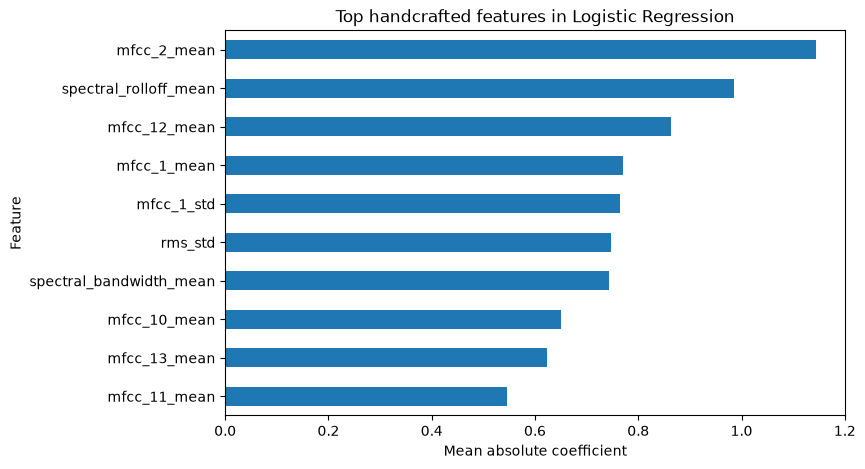

In [20]:
top_features = importance_df.head(10).sort_values(
    "importance"
)

top_features.plot(
    x="feature",
    y="importance",
    kind="barh",
    legend=False,
    figsize=(8, 5),
)

plt.xlabel("Mean absolute coefficient")
plt.ylabel("Feature")
plt.title("Top handcrafted features in Logistic Regression")
plt.show()

These values show which features are more important for this Logistic Regression model. Other models may use the features differently.

### Feature importance observations

The most important features for Logistic Regression are mainly MFCC-based, which agrees with the previous feature group comparison.

The highest importance has `mfcc_2_mean`, then by `spectral_rolloff_mean`. Several other MFCC features are also among the top features.

At the same time, `rms_std` and `spectral_bandwidth_mean` are also present in the top 10. This suggests that the model uses not only MFCCs, but also information about signal energy and spectral structure.

## Conclusions

The feature group comparison shows that MFCCs are the strongest individual group of handcrafted features for generator classification.

The best result is still achieved when all handcrafted features are used together. Spectral and energy features improve the performance beyond MFCCs alone, so they also carry useful information about the generator. Temporal features appear to contribute less.

The feature importance analysis supports the same idea. Most of the highest-ranked features are MFCC-based, but spectral rolloff, spectral bandwidth, and RMS variation also appear among the most important features.

This suggests that the acoustic fingerprint of a generator is formed by several types of signal characteristics. MFCCs seem to carry the largest part of this information, and spectral and energy features add extra details that help the model separate generators.

These results also help us decide what to test later in the project. For now, the full handcrafted feature set is the best choice because it gives the highest classification performance.

We can also try a smaller feature set based on the most informative features and compare it with the full set. If the performance stays similar, this would show that some features are not necessary.

This analysis gives us a clearer understanding of which acoustic properties matter most for generator identification and helps guide the next experiments.